# Assignment 3 — Options, Option Risk, and Portfolio Construction

**FinTech 545 — Quantitative Risk Management** · Kurt Ma

---

Each problem follows the required three-part structure: **Predict** (what I expect from
the data, a plot or the Greeks, *before* anything is fitted), **Fit**, and
**Reconcile** (whether the fit agreed, and if not, what I had missed). Every
sub-question is restated in a quote block, followed by its own code cell (labeled
`# Problem k(x)`) and the written answer. No number in the prose is typed by hand
without being printed by the code cell next to it.

The computation lives in `common.py` and `problem1.py` … `problem5.py`; this notebook
imports them, so each problem can also be run from the shell (`python problemN.py`).
Option pricing is my own code, as required: the generalized Black–Scholes–Merton
formula and its Greeks (`common.gbsm`, `common.gbsm_greeks`, a port of the class
`library/gbsm.jl`), implied volatility by root finding (`common.implied_vol`), the
CRR binomial tree for American options (`common.bt_american`) and the
non-recombining discrete-dividend tree (`common.bt_american_div`, a port of
`library/bt_american.jl`, plus a vectorised version `common.bt_div` that gives
identical values and makes $N = 500$ practical).

**Conventions** (detailed in the README): arithmetic returns; VaR and ES positive for a
loss; empirical VaR/ES with the class `RiskStats.jl` estimator; exact
$\Phi^{-1}(0.05) = -1.6449$; AICc $= -2\ln L + 2k + \frac{2k^2+2k}{n-k-1}$ counting every
fitted parameter; one seed (545) for all Monte Carlo.

*AI-use disclosure: I used an AI coding assistant (Cursor) to help write and debug the
code and to draft the write-up. I checked the pricers against the worked examples in
the Week 06/07 notes (e.g. the 2-step American put 6.4218, the converged 6.8662,
the BSM call 6.8050 and the 17% implied vol example), and every number quoted
below is printed by the code.*

In [1]:
# Setup: shared helpers and one module per problem. The notebook never recomputes
# anything itself -- it calls the part_* functions, which print every number used.
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import common
import problem1, problem2, problem3, problem4, problem5

common.use_style()
pd.set_option("display.width", 130)
print("modules loaded; seed =", common.SEED)

modules loaded; seed = 545


---

# Problem 1 — Implied Volatility from a Dirty Chain

`problem1.csv`: bid and ask for European calls and puts on XYZ at 18 strikes,
140 to 225. $S = 182.40$, today 11/13/2026, expiry 12/18/2026, $r = 4.25\%$,
continuous dividend yield $q = 0.60\%$. Time to maturity in calendar days over 365:
$T = 35/365 = 0.09589$. With a continuous yield the GBSM cost of carry is
$b = r - q = 3.65\%$ (Merton 1973, Week 06). Every quote is valued at its mid unless
a part says otherwise.

## Predict

### 1(a) Put–call parity at every strike

> *Before computing any implied volatility, check put call parity at every strike using
> the mid prices. Flag a strike only when the gap exceeds the call's spread plus the
> put's spread. Report the gap and that band at each strike. What do you conclude about
> any strike you flagged?*

With a continuous dividend yield, parity (Week 06) becomes
$C - P = S e^{-qT} - X e^{-rT}$. The gap is the market's $C - P$ minus that right-hand
side, and the band is (call ask − bid) + (put ask − bid).

In [2]:
# Problem 1(a): parity gap and band at every strike, plus a diagnosis of any flagged strike
D1 = problem1.prepare()
A1 = problem1.part_a(D1)


Problem 1(a) - put-call parity at every strike (mid prices)
S = 182.4, T = 35/365 = 0.095890, r = 0.0425, q = 0.006, b = r - q = 0.036500000000000005
S e^(-qT) = 182.2951

         C_mid   P_mid C-P (mkt) S e^-qT - X e^-rT      gap  band |gap|/band      flag
Strike                                                                                
140.0   42.950   0.090   42.8600           42.8645  -0.0045  1.40      0.003          
145.0   38.015   0.130   37.8850           37.8848  +0.0002  1.25      0.000          
150.0   33.100   0.200   32.9000           32.9051  -0.0051  1.10      0.005          
155.0   28.245   0.320   27.9250           27.9255  -0.0005  0.95      0.001          
160.0   23.480   0.535   22.9450           22.9458  -0.0008  0.83      0.001          
165.0   18.875   0.910   17.9650           17.9662  -0.0012  0.69      0.002          
170.0   14.535   1.550   12.9850           12.9865  -0.0015  0.59      0.003          
175.0   10.605   1.710    8.8950            

**Only one strike is flagged: $K = 175$.** Its gap is $+0.888$ against a band of
$0.47$, $1.9\times$ the band. Every other strike's gap is under 7 cents, at most 5% of its band.
At 140–210 the gaps are within about half a cent, which is just rounding of the quotes.

The gap tells me which leg is wrong. The market's $C - P$ at 175 is 8.895, while parity
needs 8.007. Either the call is 0.89 too rich or the put is 0.89 too cheap. Three
pieces of evidence point at the **put**:

1. The put mid of 1.71 is barely above the 170 put (1.55), even though the 180 put is 4.205.
   Parity implies a 175 put of 2.598, which sits naturally between its neighbours.
2. It breaks convexity in strike. The 165/170/175 put butterfly has a payoff that is
   never negative, yet it costs $-0.48$ at mids and **$-0.29$ at the executable bid/ask**
   (buy the 165 and 175 at the ask, sell two 170s at the bid). That is a tradable
   arbitrage if the quote were real.
3. The 175 call's price is consistent with its neighbours, which part (f) confirms in
   volatility terms.

My conclusion is that the 175 put quote is stale or mis-keyed. It should not be used to
build the smile, and it should not be read as information about XYZ.

### 1(b) What parity implies for the two implied volatilities

> *If parity holds at a strike, what must be true of the call's and the put's implied
> volatility there? Answer from the parity relation itself.*

**They must be equal.** GBSM satisfies parity *identically in σ*: for any σ,
$C_{\text{GBSM}}(\sigma) - P_{\text{GBSM}}(\sigma) = S e^{-qT} - X e^{-rT}$, because the
right-hand side has no σ in it. Suppose the market call has IV $\sigma_c$, the market
put has IV $\sigma_p$, and the market prices satisfy parity. Then

$$C(\sigma_c) - P(\sigma_p) = S e^{-qT} - X e^{-rT} = C(\sigma_p) - P(\sigma_p)
\;\Rightarrow\; C(\sigma_c) = C(\sigma_p).$$

The call value is strictly increasing in σ (vega $> 0$), so $\sigma_c = \sigma_p$.
In practice parity only holds to within the band, so the two IVs agree to within
roughly (parity gap)/vega. I expect call and put IVs to lie on top of each other at
every strike except 175.

### 1(c) Which quotes will give the least reliable IVs

> *Using vega, say which quotes you expect to give the least reliable implied
> volatilities, and why. Look at the quotes in the far wings before you answer.*

IV is the price inverted through the pricing function, so a price error $\varepsilon$
becomes an IV error of about $\varepsilon/\text{vega}$. The reliability of an IV
depends on the ratio *spread / vega*: how many vol points the bid–ask range spans.
Vega is largest at the money and falls toward zero in both wings. Before computing
any IV, the table below evaluates vega at a single flat 25% vol for every strike.

In [3]:
# Problem 1(c): vega at a flat 25% vol (no IVs yet) against the quoted spreads
C1 = problem1.part_c(D1)


Problem 1(c) - vega at a flat 25% vol vs the quoted spreads
       vega@25%   C_mid C_spr C spr/vega (vol pts)   P_mid P_spr P spr/vega (vol pts)
Strike                                                                               
140.0     0.049  42.950  1.34              2732.70   0.090  0.06               122.36
145.0     0.216  38.015  1.19               550.03   0.130  0.06                27.73
150.0     0.747  33.100  1.04               139.26   0.200  0.06                 8.03
155.0     2.062  28.245  0.89                43.15   0.320  0.06                 2.91
160.0     4.648  23.480  0.76                16.35   0.535  0.07                 1.51
165.0     8.703  18.875  0.61                 7.01   0.910  0.08                 0.92
170.0    13.750  14.535  0.49                 3.56   1.550  0.10                 0.73
175.0    18.595  10.605  0.37                 1.99   1.710  0.10                 0.54
180.0    21.800   7.230  0.26                 1.19   4.205  0.17               

**Prediction.** Near the money (180–200) the out-of-the-money leg's spread spans about
0.5–1.2 vol points, so those IVs will be tight. The least reliable quotes are in the **far wings, on both legs**,
for two different reasons:

* **Deep in-the-money quotes** (calls 140–155, puts 205–225). Vega is tiny (0.05–2) while
  the dollar spread is wide (0.9–1.3). The spread spans tens to *thousands* of vol points.
  The price is almost all discounted intrinsic value, and the time value that carries
  the volatility information is a few cents. I expect some bids to sit below intrinsic,
  where no IV exists.
* **Deep out-of-the-money quotes** (puts 140–150, calls 210–225). These are quoted at
  5–20 cents, near the minimum tick. A 5-cent spread is 30–100% of the price, and vega
  is small. Calls 215, 220 and 225 all show the *same* quote, 0.05 / 0.10. Three
  different strikes cannot be worth the same, so these are tick-bound placeholders, not
  prices. I expect their IVs to be artifacts.

## Fit

### 1(d) IV from the bid, the mid and the ask; the smile plot

> *Compute the implied volatility of every quote from its mid, and also from its bid and
> from its ask. Some quotes may not have an implied volatility at one of the three. If
> so, say why. Plot the call and the put implied volatility against strike on one chart.*


Problem 1(d) - implied vol of every quote from its bid, mid and ask

Calls
        IV_bid  IV_mid  IV_ask intrinsic_disc                                              why
Strike                                                                                        
140.0           0.3880  0.5647         42.864  bid: price 42.28 <= discounted intrinsic 42.864
145.0           0.3643  0.4997         37.885  bid: price 37.42 <= discounted intrinsic 37.885
150.0           0.3395  0.4395         32.905  bid: price 32.58 <= discounted intrinsic 32.905
155.0           0.3198  0.3880         27.925  bid: price 27.80 <= discounted intrinsic 27.925
160.0   0.2344  0.3017  0.3462         22.946                                                 
165.0   0.2550  0.2858  0.3126         17.966                                                 
170.0   0.2550  0.2720  0.2883         12.986                                                 
175.0   0.2506  0.2605  0.2702          8.007                        

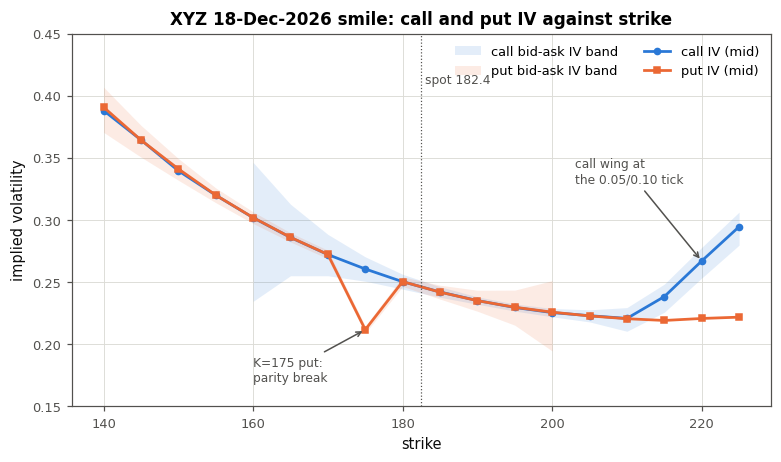

In [4]:
# Problem 1(d): IV from bid / mid / ask for every quote (Brent root-finding on GBSM, b = r - q)
IV1 = problem1.part_d(D1)
problem1.figure_smile(D1)

Every mid and every ask has an IV. **Nine bids do not: the calls at 140–155 and the
puts at 205–225, all deep in the money.** The reason is the same in each case. As
$\sigma \to 0$ the GBSM value falls to the discounted forward intrinsic,
$\max(0, Se^{-qT} - Xe^{-rT})$ for a call. These bids are *below* that floor (e.g. the
140 call bid is 42.28 against a floor of 42.864). No non-negative volatility can price
an option below its zero-volatility value, so the root finder has no root. These bids
are below a no-arbitrage bound. A market maker can show them because nobody would
ever sell at that price; they are not executable information.

The chart shows the two legs lying on top of each other from 140 to 210, as 1(b)
requires. Two things stand out: the 175 put falls 5 points below the curve, and the
calls above 210 turn sharply upward while the puts at the same strikes stay flat.

### 1(e) Vega and the IV change per one cent

> *Compute vega at each strike, and the change in implied volatility that a one cent
> change in price produces.*

In [5]:
# Problem 1(e): vega at each quote's mid IV, and 1 cent / vega in vol points
V1 = problem1.part_e(D1)


Problem 1(e) - vega (at each quote's mid IV) and dIV for a 1 cent move


       vega Call vega Put dIV/1c Call dIV/1c Put
Strike                                          
140.0     1.6318   1.6886      0.6128     0.5922
145.0     2.3732   2.3710      0.4214     0.4218
150.0     3.3902   3.4441      0.2950     0.2904
155.0     5.0566   5.0609      0.1978     0.1976
160.0     7.4599   7.4655      0.1340     0.1339
165.0    10.7449  10.7504      0.0931     0.0930
170.0    14.7579  14.7621      0.0678     0.0677
175.0    18.8417  17.4008      0.0531     0.0575
180.0    21.8006  21.8009      0.0459     0.0459
185.0    22.3970  22.3968      0.0446     0.0446
190.0    20.1044  20.1020      0.0497     0.0497
195.0    15.6218  15.6327      0.0640     0.0640
200.0    10.5050  10.5300      0.0952     0.0950
205.0     6.1876   6.1734      0.1616     0.1620
210.0     3.1927   3.1774      0.3132     0.3147
215.0     2.2580   1.4603      0.4429     0.6848
220.0     2.0733   0.6582      0.4823     1.5193
225.0     1.9250   0.2716      0.5195     3.6815

dIV per 1c is in vo

At the money, vega is about 22 per unit of volatility, so one cent moves IV by
**0.045 vol points**. In the wings the same cent is worth 10–80 times more. It moves
IV by 0.44–0.52 points on the 215–225 calls, 0.6 points on the 140 call and put, and
**3.7 points on the 225 put**, whose vega is 0.27. This quantifies 1(c): a
quote error that is invisible in dollars is large in volatility wherever vega is
small.

## Reconcile

### 1(f) The flagged strike in vol points

> *Did the strike flagged by parity show up in the plot? Translate its parity gap into
> vol points using vega, and check that against the gap between its call and put
> implied volatility.*

In [6]:
# Problem 1(f): the K=175 parity gap divided by vega, against the call-put IV gap
F1 = problem1.part_f(D1, A1)


Problem 1(f) - the K=175 parity gap in vol points
parity gap (call - put - parity)  = +0.8882 dollars
vega at K=175 (put IV 0.2116)  = 17.401 per 1.00 vol
vega at K=175 (call IV 0.2605) = 18.842 per 1.00 vol
gap / vega                         = 5.10 to 4.71 vol points
call IV - put IV (mid)             = 4.88 vol points
put IVs either side (170, 180) avg = 0.2612;  call IV at 175 = 0.2605
-> the CALL sits on the smile, the PUT is ~5 vol points too low: the put quote
   is the bad leg (stale / mis-keyed). Its mid 1.71 is barely above the
   170 put's 1.55, while parity implies 2.598.


**Yes.** The 175 put is the notch in the put curve. The parity gap of \$0.888 divided by
vega (17.4 at the put's IV, 18.8 at the call's) is **4.7 to 5.1 vol points**. The
measured call–put IV gap is **4.88 points**, inside that range, so the gap is
entirely explained by one bad price. The call IV at 175 (0.2605) matches the average
of the put IVs at 170 and 180 (0.2612), so the call is on the smile and the put is
about 5 points below it. This confirms the diagnosis in (a).

### 1(g) The call wing above 210

> *Describe the call wing above 210. Is that shape a statement about the market, or about
> the quotes? Use your answer to part (e) and the bid and ask implied volatilities to
> decide, and explain why parity did not catch it.*

In [7]:
# Problem 1(g): the call wing -- quotes, bid/mid/ask IVs, put IV at the same strike,
#               and the call price the put's IV implies
G1 = problem1.part_g(D1, A1)


Problem 1(g) - the call wing above 210
       C_bid C_ask C IV bid C IV mid C IV ask P IV mid spread (vol pts) C @ put IV parity band   |gap|
Strike                                                                                                
200.0   0.61  0.68   0.2220   0.2254   0.2286   0.2257             0.67     0.6485        0.65  0.0035
205.0   0.25  0.31   0.2179   0.2229   0.2276   0.2227             0.97     0.2788        0.78  0.0012
210.0   0.08  0.14   0.2103   0.2207   0.2294   0.2204             1.91     0.1092        0.92  0.0008
215.0   0.05  0.10   0.2256   0.2382   0.2483   0.2190             2.26     0.0395        1.05  0.0355
220.0   0.05  0.10   0.2531   0.2669   0.2778   0.2206             2.47     0.0148        1.20  0.0602
225.0   0.05  0.10   0.2796   0.2945   0.3062   0.2217             2.66     0.0052        1.36  0.0698

Calls 215/220/225 all quote exactly 0.05 / 0.10: the minimum tick, not a price.
On the put-implied smile they are worth 0.02-0.04, belo

The call mid IV turns up from 22.1% at 210 to 23.8%, 26.7% and 29.5% at 215, 220 and
225. **This shape comes from the quotes, not the market.**

* All three strikes are quoted exactly **0.05 / 0.10**. A further OTM call must be
  cheaper, so three identical prices are a floor, not a valuation.
* At the puts' IV (≈22%, which parity says the calls should share) the calls are worth
  0.040, 0.015 and 0.005. Those values are below the 0.05 minimum bid, so the quote
  cannot go lower and the inverted IV must rise with strike.
* Even the **bid** IV rises (22.6% → 25.3% → 28.0%). With a cent worth about 0.5 vol
  points there (part (e)), the 5-cent tick alone is 2.3–2.7 vol points of bid–ask
  width. The fixed tick in dollars is mapped onto a falling vega, which mechanically
  produces an upward curve.

**Why parity did not catch it.** Parity is checked in dollars, and the dollar error is
small: the calls are 4–7 cents too rich, and those are exactly the gaps at 215–225
(0.036, 0.060, 0.070). The band at those strikes is set by the *deep ITM put's* spread
(1.00–1.31), so the total band is 1.05–1.36. A 7-cent error is invisible against a
\$1.36 band, but because the call's vega is about 2, it is worth 3–7 vol points. Parity
catches errors that are large in dollars (the 175 put). Errors that are small in dollars
but large in vol points are caught only in vol space, at the strikes where vega is small.

### 1(h) The shape of the clean smile

> *Ignoring the two problems you found, describe the shape of the smile. What does it say
> about demand for downside protection on XYZ?*

In [8]:
# Problem 1(h): the smile from the OTM leg at each strike, with the clean leg substituted
#               at K=175 (call) and at K>=215 (put)
H1 = problem1.part_h(D1)


Problem 1(h) - clean smile (OTM leg; * = other leg substituted)
       moneyness K/S    leg      IV
Strike                             
140.0          0.768    Put  0.3907
145.0          0.795    Put  0.3642
150.0          0.822    Put  0.3410
155.0          0.850    Put  0.3199
160.0          0.877    Put  0.3018
165.0          0.905    Put  0.2859
170.0          0.932    Put  0.2722
175.0          0.959  Call*  0.2605
180.0          0.987    Put  0.2503
185.0          1.014   Call  0.2419
190.0          1.042   Call  0.2350
195.0          1.069   Call  0.2295
200.0          1.096   Call  0.2254
205.0          1.124   Call  0.2229
210.0          1.151   Call  0.2207
215.0          1.179   Put*  0.2190
220.0          1.206   Put*  0.2206
225.0          1.234   Put*  0.2217

ATM IV (interpolated at S) = 0.2463
IV at 90% of spot = 0.2886 (+4.2 pts), IV at 110% of spot = 0.2250 (-2.1 pts)


With the bad quotes removed the smile is a **downward-sloping skew (a "smirk")**. IV is
39% at 140 (77% of spot), falls steadily to 24.6% at the money and flattens at
22% above 205. The slope is steep on the downside and shallow on the upside: 90% of
spot trades 4.2 points over ATM, while 110% of spot is only 2.1 points under it.

Because the OTM puts are priced at much higher volatility than equidistant OTM calls,
the market is **paying up for downside protection**. Holders of XYZ buy puts and
collars, and the risk-neutral distribution implied by these prices has a fatter
left tail than the lognormal (negative skew). At a flat 24.6% the 140 put
would be worth \$0.0007, but the market charges 9 cents, more than 100 times as much,
for protection against a 23% fall in five weeks. This is the typical equity skew.

---

# Problem 2 — American Options and Discrete Dividends

$S = 48.50$, $X = 50$, $T = 0.5$, $r = 4.5\%$, $\sigma = 30\%$. Dividends of \$0.25 at
$t = 0.10$ and \$1.50 at $t = 0.40$. Those are $T/5$ and $4T/5$, so with $N$ a multiple
of 5 the dividends fall on steps $N/5$ and $4N/5$. The headline numbers use $N = 500$.

Tree conventions follow `bt_american.jl` (Week 07). Between dividends the stock grows at
$r$ ($b = r$). On a dividend step, *holding* continues on a fresh sub-tree started at
$S_{node} - D$, while *exercising* pays the cum-dividend payoff $\pi(S_{node})$ ("the
holder exercises and receives the dividend"). The European option with dividends is
the same tree with the exercise branch switched off.

## Predict

### 2(a) Hull's early-exercise condition

> *Apply the condition from Week 7, $D_n > X(1 - e^{-r(T - t_n)})$, to each dividend. Just
> before which dividend, if either, can early exercise of the American call be optimal?*

In [9]:
# Problem 2(a): D_n against the interest on the strike from t_n to T
A2 = problem2.part_a()


Problem 2(a) - early exercise condition D_n > X(1 - e^{-r(T - t_n)})
           t_n   D_n T - t_n X(1-e^-r(T-t_n))  D_n > threshold
dividend                                                      
D1        0.10  0.25    0.40           0.8919            False
D2        0.40  1.50    0.10           0.2245             True

-> exercise can be optimal only just before D2 (t = 0.40);
   D1 is worth less than the interest on the strike it would forgo.


The right-hand side is the interest earned on the strike by *not* paying it until
maturity. For D1, the 25 cents is worth less than the 89 cents of interest on \$50 over
the remaining 0.4 years, so exercising just before D1 is never optimal. For D2, the
\$1.50 is far more than the 22 cents of interest over the last 0.1 years. **Early
exercise of the call can be optimal only just before the second dividend**, and only
at nodes deep enough in the money that the remaining time value is below the
dividend.

### 2(b) Predicted direction of each dividend effect

> *Without computing anything, predict for each of the four options whether the dividends
> raise or lower its value, and which of the two early exercise premiums, call or put,
> the dividends make larger.*

The stock drops by each dividend on its ex-date, and the option holder does not receive
it. So the dividends lower the expected stock price at expiry.

| option | prediction | reason |
|---|---|---|
| European call | **lower** | lower expected terminal price |
| American call | **lower**, but by less than the European | it can exercise just before D2 and capture the dividend |
| European put | **higher** | lower expected terminal price |
| American put | **higher**, but by less than the European | dividends make waiting more attractive (see below) |

**Early exercise premiums.** Without dividends the American call premium is exactly zero
(Week 07). With a \$1.50 dividend that can be captured by exercising, the **call
premium rises from zero to something material**. The put goes the other way: exercising
a put early gives up the stock price drop the dividend is about to cause. A put holder
wants to wait for the dividend, so the dividends should make the **put premium
smaller**. The dividends therefore make the call's premium larger and the put's
smaller, and I expect the call's to end up larger than the put's.

## Fit

### 2(c) The four options without and with dividends

> *Price all four options without dividends, using GBSM for the Europeans and a tree for
> the Americans. Then price all four with the dividends, using the non recombining tree.
> For the European options, also report GBSM with the present value of the dividends taken
> off the stock price, and compare it with the tree.*

In [10]:
# Problem 2(c): no-dividend GBSM / tree, discrete-dividend non-recombining tree, escrowed GBSM
P2 = problem2.part_c()


Problem 2(c) - prices without and with dividends (tree N = 500)
PV of dividends = 0.25 e^(-r 0.1) + 1.50 e^(-r 0.4) = 1.7221;  S* = S - PV = 46.7779

              no dividends with dividends (tree) GBSM on S - PV(D) change from dividends
European call       3.9223                3.1763            3.0723               -0.7460
American call       3.9241                3.4695                                 -0.4546
European put        4.3098                5.2860            5.1820                0.9761
American put        4.4394                5.3714                                  0.9320

No-dividend Europeans by GBSM; on the same N=500 tree they are 3.9241 (call) and 4.3116 (put).
Tree European minus escrowed GBSM: call +0.1040, put +0.1040
  (the tree applies 30% vol to the whole cum-dividend price; the escrowed
   model applies it only to S - PV(D), a smaller base, so its effective
   dollar volatility is lower and both options come out a little cheaper)


The directions match 2(b). The European call falls by 0.746, the American call by only
0.455, the European put rises by 0.976 and the American put by 0.932. Without dividends
the American call equals the European on the same tree (3.9241 both), as Week 07 says
it must.

**Tree against escrowed GBSM.** Subtracting the PV of the dividends (1.7221) gives
$S^* = 46.778$, and GBSM on $S^*$ prices both Europeans exactly **0.104 lower** than the
tree. That the call and put differences are identical is parity at work: both models
have the same forward, so the difference must be a pure volatility effect. The tree
puts 30% volatility on the whole cum-dividend price. The escrowed model puts 30% on
$S - PV(D)$ only, so its dollar volatility is smaller by about $1.72/48.5 = 3.6\%$.
The escrowed model reproduces the tree's European call at a vol of 30.8%, and with
vega ≈ 13.1 the 0.8-point difference is worth 0.10. Neither is "right". They are two
assumptions about what is volatile.

### 2(d) Convergence in $N$

> *Show how the American values converge as $N$ grows. Include neighbouring values of $N$,
> such as 100 and 105.*


Problem 2(d) - convergence of the American values in N
     Am call (div) Am put (div) Am call (no div) Am put (no div)
N                                                               
50         3.47152      5.36798          3.94213         4.45748
55         3.48417      5.38451          3.90774         4.43110
100        3.47265      5.37932          3.92831         4.44374
105        3.46512      5.36824          3.92624         4.44350
200        3.46754      5.37114          3.91760         4.43528
205        3.46723      5.37283          3.92707         4.44244
300        3.46996      5.37208          3.92377         4.43970
305        3.46971      5.37066          3.92379         4.43932
500        3.46945      5.37140          3.92407         4.43942
1000       3.46788      5.36983          3.92283         4.43829
N=100 -> 105: call -0.00753, put -0.01108
N=200 -> 205: call -0.00031, put +0.00169
N=300 -> 305: call -0.00025, put -0.00142

Range of values for N in [200, 500]: 

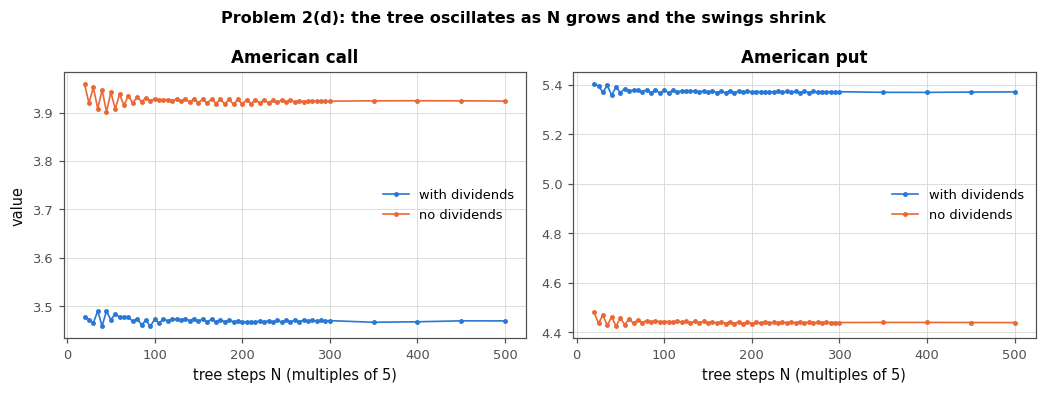

In [11]:
# Problem 2(d): American values for N = 20, 25, ..., 500 (and 1000), with and without dividends
Dd2 = problem2.part_d()
problem2.figure_convergence(Dd2)

The tree converges **in an oscillation, not monotonically**. Moving from $N=100$ to
$N=105$ changes the call by $-0.0075$ and the put by $-0.011$, roughly a third of a
cent per step of 5 in each direction. By $N = 200$–$500$ the swings fall to under half
a cent (range 0.0047), and $N=1000$ moves both values by another 0.0016. The cause is
where the strike falls relative to the terminal nodes: as $N$ changes, the node nearest
$X$ moves above or below it, and the payoff kink is sampled differently. The lesson is
the one from Week 07, "use enough steps", plus a second: the error at a single $N$ is
not a smooth function of $N$, so averaging neighbouring $N$ is a better estimate than
either alone. At $N = 500$ the numbers are good to about ±0.002.

### 2(e) Delta and gamma by central differences

> *Compute the delta and the gamma of the two American options by central finite
> differences on the tree, with bump sizes of 1, 0.1, 0.01, and 0.001.*

In [12]:
# Problem 2(e): delta = [V(S+h) - V(S-h)]/2h, gamma = [V(S+h) + V(S-h) - 2V(S)]/h^2, N = 500
E2 = problem2.part_e()


Problem 2(e) - tree delta and gamma by central differences (N = 500)
                   delta     gamma
option  bump h                    
Am call 1.000    0.50241   0.04088
        0.100    0.50518   0.00035
        0.010    0.50519   0.00025
        0.001    0.50519  -0.00000
Am put  1.000   -0.54735   0.03913
        0.100   -0.54877   0.00612
        0.010   -0.54876   0.00589
        0.001   -0.54876   0.00638

Smooth reference (European GBSM on S - PV(D)):
  call delta 0.45942 gamma 0.04000; put delta -0.54058 gamma 0.04000


**Delta** is stable: $0.5052$ for the call and $-0.5488$ for the put at every bump from
0.1 down. **Gamma** is not. At $h = 1$ it is 0.041 (call) and 0.039 (put), close to the
smooth reference of 0.040. At $h \le 0.1$ the call's gamma collapses to
$0.0003$ and then $0.0000$, and the put's falls to 0.006 and wanders. Part (h) explains why.

### 2(f) Sensitivity to each dividend

> *Compute the sensitivity of each option's value to each dividend amount.*

In [13]:
# Problem 2(f): dV/dD_k by central difference (h = 1 cent) on the N = 500 tree
F2 = problem2.part_f()


Problem 2(f) - dV/dD_k by central difference (h = 0.01, N = 500)
dividend                D1 (t=0.1) D2 (t=0.4)
Euro call                  -0.4411    -0.3863
Am call                    -0.4851    -0.1055
Euro put                   +0.5545    +0.5958
Am put                     +0.5632    +0.6050
Euro call (escrow GBSM)    -0.4574    -0.4512
Euro put (escrow GBSM)     +0.5381    +0.5309


Per dollar of dividend, the **American call loses \$0.49 for D1 but only \$0.11 for D2**.
Puts gain \$0.55–0.61 per dollar of either dividend. For the European call the two
dividends have similar effects (−0.44, −0.39); under the escrowed GBSM they are
essentially equal (−0.457, −0.451, differing only by $e^{-rt}$). The large asymmetry
appears only in the American call. Part (i) explains it.

## Reconcile

### 2(g) Early exercise premiums, and the exercise boundary before D2

> *Report the early exercise premium of each option, with and without dividends. Did your
> predictions in parts (a) and (b) hold? For the call, find the stock price above which
> exercise just before the second dividend is optimal.*

In [14]:
# Problem 2(g): American - European on the same tree; critical stock price just before D2
G2 = problem2.part_g(P2)


Problem 2(g) - early exercise premium = American - European (same tree)
                          no dividends with dividends   change
call: American - European      +0.0000        +0.2932  +0.2932
put: American - European       +0.1278        +0.0854  -0.0423

Critical stock price just before D2 (t = 0.40): S* = 52.7168
  at S*: exercise value 2.7168 = hold value 2.7168
  tree check (N=500), nodes at step 400: highest node held = 52.3242, lowest node exercised = 53.3264


| premium | no dividends | with dividends |
|---|---|---|
| call | 0.0000 | **0.2932** |
| put | 0.1278 | **0.0854** |

**Both predictions held.** The dividends switch on the call's early exercise premium
(zero to 0.29), and they shrink the put's from 0.128 to 0.085, so the call premium ends
up the larger of the two. The direction of every price change in 2(b) is correct.

**The exercise boundary just before D2 is $S^* = 52.72$.** At $t = 0.40$, cum-dividend,
the holder compares exercising ($S - 50$, then collecting the stock's dividend) with
holding a call on the ex-dividend stock $S - 1.50$ with 0.1 years left and no further
dividends. That call cannot be exercised early, so it is worth its GBSM value. The
indifference point solves $S - 50 = C_{\text{GBSM}}(S - 1.50, 50, 0.1)$, giving
$S^* = 52.72$. The $N=500$ tree agrees: at step 400 the highest node it holds is 52.32
and the lowest it exercises is 53.33, which bracket $S^*$. Part (a) said exercise
*can* be optimal before D2. Part (g) says it is optimal only when the stock is above
52.72 at that date, about 8.7% above today's price.

### 2(h) Which Greek does not settle, and why

> *One of your Greeks in part (e) does not settle down as the bump shrinks. Which one, and
> why? Think about what the tree's value looks like as a function of the stock price when
> $N$ is fixed.*

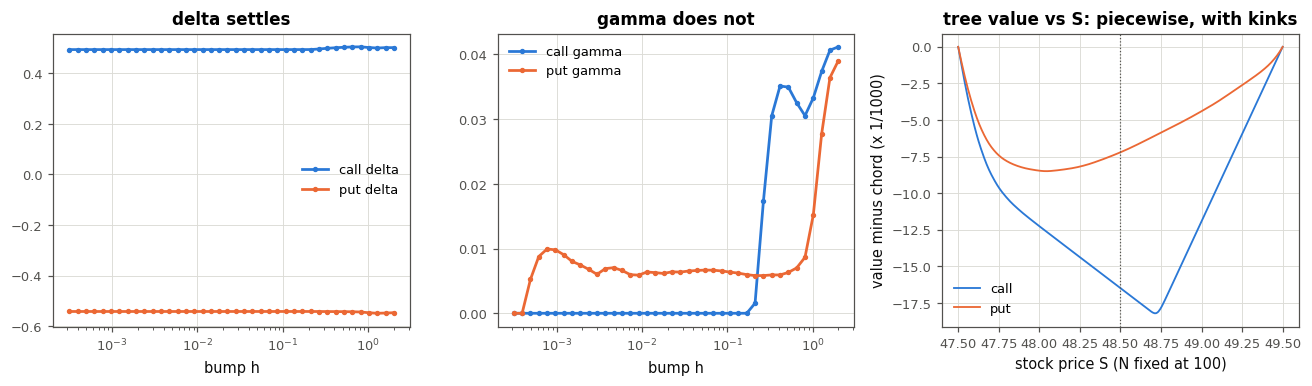


Problem 2(h) - why gamma does not settle (tree N = 100)
Root node spacing S(u - d) at N=100: 2.058; at N=500: 0.920
  call: 399 prices 47.5..49.5 (step 0.005): second difference ~0 at 54% of them, max |gamma| 0.830
  put: 399 prices 47.5..49.5 (step 0.005): second difference ~0 at 0% of them, max |gamma| 0.402
         call_delta put_delta call_gamma put_gamma
h                                                 
0.000316    0.49445  -0.54224   -0.00000   0.00000
0.000971    0.49445  -0.54224   -0.00000   0.00980
0.002981    0.49445  -0.54225   -0.00000   0.00602
0.009152    0.49445  -0.54224   -0.00000   0.00589
0.028101    0.49445  -0.54224   -0.00000   0.00636
0.086277    0.49445  -0.54220    0.00000   0.00654
0.264897    0.49674  -0.54235    0.01728   0.00583
0.813311    0.50529  -0.54423    0.03053   0.00865
1.995262    0.50211  -0.54713    0.04117   0.03902


In [15]:
# Problem 2(h): delta and gamma over 40 bump sizes, and the tree value as a function of S
#               (N = 100 for the figure; the argument does not depend on N)
G2h, V2h = problem2.gamma_vs_bump(), problem2.value_curve()
problem2.figure_greeks(G2h, V2h)
problem2.part_h(G2h, V2h)

**Gamma.** On a CRR tree, $u = e^{\sigma\sqrt{\Delta t}}$ and $d = 1/u$ do not depend on
$S$, so every node price is $S$ times a constant (minus a fixed dividend after the
dividend steps). Each node's payoff, $\max(0, S u^i d^{N-i} - X)$ and its American
$\max(\text{exercise}, \text{continue})$, is therefore **piecewise linear in $S$**. A sum
of discounted piecewise-linear functions is piecewise linear. At fixed $N$, the tree's
value as a function of $S$ is a chain of straight segments joined at kinks, where some
node crosses the strike or the exercise boundary. The right panel shows this: the call's
value curve, with the chord removed, is made of straight segments with a sharp corner
near 48.75.

Gamma is a second difference, so it measures curvature. With a bump smaller than the
distance to the nearest kink, all three evaluations sit on one straight segment and the
estimate is exactly zero (the call at $h \le 0.1$). If a kink falls inside the bump,
the estimate jumps to (change in slope)/$h$, which grows as $h$ shrinks. The put has
many more kinks, one from every sub-tree's exercise boundary, so its estimate wanders
rather than collapsing. **Delta** is a first difference and only needs the *average*
slope, which is stable, so it settles.

The bump has to be at least comparable to the node spacing $S(u - d)$ (0.92 at
$N = 500$), so that it averages over many kinks. That is why $h = 1$ recovers the smooth
0.040 and $h = 0.001$ does not. The class homework found the same thing ("need to play
with the offset value to get a good derivative").

### 2(i) Why the two dividends move the call so differently

> *The two dividends move the call by very different amounts per dollar. Explain why,
> using part (a).*

D1 fails Hull's test, so the call is **never** exercised before it. In every state of
the world the holder sits through the D1 ex-date and the stock drops by D1. The call
loses roughly delta × PV(D1) per dollar: **−0.49**, the same order as its delta of 0.5.

D2 passes the test. In every state where the stock is above $S^* = 52.72$ at $t = 0.40$,
the holder exercises just before D2, owns the stock and *collects* the dividend. In
those states the call's value is $S - X$, which does not depend on $D_2$ at all. D2
reaches the call's value only in the states below $S^*$, where the call is held, and
there the call's delta is low. Raising D2 also lowers $S^*$, so more states switch to
exercise. Together these give only **−0.11 per dollar**, less than a quarter of
D1's effect. The early exercise right is a hedge against the second dividend, and part
(a) is the test of whether that hedge exists.

---

# Problem 3 — VaR of an Option Book

`problem3.csv`: 501 daily ABC prices, giving 500 arithmetic returns. Everything is valued
at the last price, $S_0 = 99.12$, with $r = 4.25\%$, no dividends ($b = r$),
$T = \text{DaysToExpiry}/255$, implied vols held fixed, a 10-trading-day horizon and
zero expected return. The four books:

| book | positions |
|---|---|
| CoveredCall | +100 ABC, −100 calls K=105 (IV 27%) |
| ShortStraddle | −100 calls and −100 puts K=100 (IV 29%) |
| RiskReversal | +100 calls K=105 (27%), −100 puts K=95 (32%) |
| HedgedShortCall | −100 calls K=100 (29%), +50 ABC |

## Predict

### 3(a) Book Greeks, and how badly delta-normal will misstate each book

> *Compute each book's delta, gamma, and theta. Before you simulate anything, rank the four
> books by how badly you expect a delta normal VaR to misstate their 10 day risk, and say
> whether it overstates or understates. Use the Greeks to justify the ranking.*

In [16]:
# Problem 3(a): position and book Greeks (closed-form GBSM, Week 07); size of each Taylor
#               term for a one-standard-deviation 10-day move
D3 = problem3.prepare()
B3 = problem3.part_a(D3)


Problem 3(a) - position and book Greeks
S0 = 99.12, T = DaysToExpiry/255, r = b = 0.0425

                      Strike Holding unit value unit delta     value     delta    gamma theta/day  vega/pt
Portfolio       Type                                                                                      
CoveredCall     Stock            100    99.1200     1.0000  9,912.00  +100.000  +0.0000   +0.0000   +0.000
                Call     105    -100     1.6722     0.3008   -167.22   -30.084  -3.7925   +5.7952  -11.836
ShortStraddle   Call     100    -100     3.7516     0.5044   -375.16   -50.444  -4.0461   +7.3260  -13.562
                Put      100    -100     4.1328    -0.4956   -413.28   +49.556  -4.0461   +5.6676  -13.562
RiskReversal    Call     105     100     1.6722     0.3008    167.22   +30.084  +3.7925   -5.7952  +11.836
                Put       95    -100     2.3301    -0.3130   -233.01   +31.305  -3.2566   +5.8681  -12.045
HedgedShortCall Call     100    -100     3.7516     0

Delta-normal sees only the first term of $\Delta P \approx \delta\,\Delta S +
\tfrac12\Gamma(\Delta S)^2 + \Theta\,\Delta t$. How badly it misstates a book depends on
how much of the book's risk sits in the gamma term. For a one-standard-deviation 10-day
move ($\Delta S = \$5.23$), the "gamma share" column measures this:

| rank | book | delta (sh) | gamma | gamma share | prediction |
|---|---|---|---|---|---|
| 1 | **ShortStraddle** | −0.9 | −8.09 | 96% | delta-normal VaR ≈ \$8, **massively understates** |
| 2 | **HedgedShortCall** | −0.4 | −4.05 | 96% | ≈ \$4, **massively understates** |
| 3 | CoveredCall | +69.9 | −3.79 | 12% | **understates** moderately; the short call adds losses on a fall |
| 4 | RiskReversal | +61.4 | +0.54 | 2% | about right; **slightly overstates**, because small positive gamma cushions the downside |

The two delta-neutral books carry almost all their risk in the second-order term, and
short gamma means that term is a loss for a move in *either* direction. Delta-normal
reports near-zero risk for both. The straddle ranks first because its gamma is twice
as large. In proportional terms the two will be similarly wrong (both by a factor
of 30–40×). The covered call's short gamma (−3.79) is small next to its delta, so the
error there is a few percent to around 15%, in the understating direction.

### 3(b) The no-move P&L, and which books will have fat ES/VaR

> *For each book, predict the sign of the P&L if the price does not move for 10 days. Then
> predict which books will have an ES to VaR ratio well above the 1.25 a normal P&L would
> give.*

**No-move P&L** is pure theta. From the table above, $\Theta \times 10$ days is
**positive for every book**: CoveredCall +\$58, ShortStraddle +\$130, HedgedShortCall
+\$73. All three are net short options and collect time decay. The RiskReversal is
close to zero (+\$0.7) because its long call's decay nearly offsets its short put's.
The exact numbers are revalued in 3(h).

**ES/VaR.** A loss that is quadratic in $\Delta S$ grows faster than linearly in the
tail, so the average loss beyond VaR is far above VaR itself. I predict
**ShortStraddle and HedgedShortCall** will have ES/VaR well above 1.25 (around 1.5),
since their whole distribution is $-\tfrac12|\Gamma|\Delta S^2$, a scaled
chi-square with one degree of freedom whose left tail is long. CoveredCall will be
slightly above 1.25, because the short call adds a little left skew. RiskReversal will
be near 1.25, since it is close to linear.

## Fit

### 3(c) Moments; Normal against Student $t$

> *Compute the first four moments of the returns. Fit a normal and a Student's $t$ and choose
> between them with AICc. Report the fitted parameters.*


Problem 3(c) - moments of ABC returns; Normal vs Student t by AICc
n = 500  mean = 0.000321  sd = 0.016674  skew = 0.0191  excess kurtosis = 2.4639
se(skew) ~ sqrt(6/n) = 0.110, se(exkurt) ~ sqrt(24/n) = 0.219

                     Normal     Student t
mu                 0.000321      0.000001
sigma / scale      0.016658      0.013506
nu                               5.789259
implied sd         0.016658      0.016694
log-lik         1337.975050   1353.198522
k                  2.000000      3.000000
AICc           -2671.925956  -2700.348656

delta AICc (Normal - t) = 28.42  ->  Student t preferred


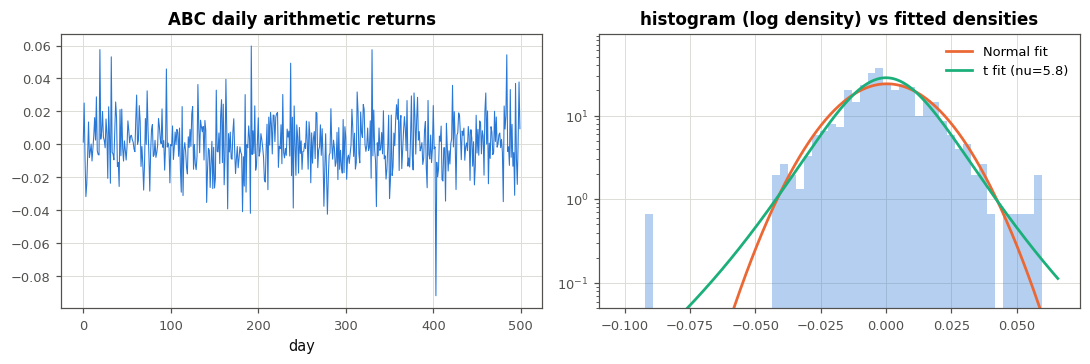

In [17]:
# Problem 3(c): moments, Normal and t MLE fits, AICc (k = 2 and 3)
FIT3 = problem3.part_c(D3)
problem3.figure_returns(D3)

The returns have mean 0.032% a day, sd 1.667% (26.6% a year, slightly below every
implied vol in the books), skew 0.02 (not significant, se 0.11) and **excess
kurtosis 2.46** (11 standard errors). The **Student $t$ wins by 28.4 AICc units**:
$\nu = 5.79$, scale 0.01351 (implied sd 0.01669, nearly identical to the Normal's), and
location essentially zero. Both fits have the same variance. The $t$ redistributes
probability from the shoulders to the centre and the tails.

### 3(d) 10-day delta-normal VaR and ES

> *Compute the 10 day delta normal VaR and ES for each book at 5% and 1%.*

Dollar delta is $\Delta_\$ = \sum_i h_i\,\delta_i\,S_0$. The 10-day return sd is
$\sigma\sqrt{10}$, with σ the sample sd and the mean set to zero. Then
$\text{VaR}_\alpha = -\Phi^{-1}(\alpha)\,\sigma_{10}|\Delta_\$|$ and
$\text{ES}_\alpha = \sigma_{10}\,\phi(\Phi^{-1}(\alpha))/\alpha\cdot|\Delta_\$|$
(Week 04 §4.4; Week 07 homework).

In [18]:
# Problem 3(d): delta-normal VaR / ES over 10 days
DN3 = problem3.part_d(D3)


Problem 3(d) - 10-day delta-normal VaR and ES ($, positive = loss)
sigma_daily = 0.016674, sigma_10 = 0.052729

                   $delta    VaR5     ES5    VaR1     ES1
Portfolio                                                
CoveredCall      6,930.08  601.05  753.74  850.08  973.91
ShortStraddle      -88.10    7.64    9.58   10.81   12.38
RiskReversal     6,084.85  527.75  661.81  746.40  855.12
HedgedShortCall    -44.05    3.82    4.79    5.40    6.19


### 3(e) Simulation and full revaluation

> *Simulate 10 daily returns from each fitted distribution with zero mean, compound them,
> and revalue every position in full with 10 fewer days to expiry. Report the mean P&L,
> and VaR and ES at 5% and 1%, for each book under each distribution.*

100,000 paths per distribution. Each path is 10 i.i.d. daily returns from the fitted
model with its location set to 0, compounded as $S_{10} = S_0\prod(1+r_i)$. Each
option is repriced by GBSM at $S_{10}$ with $T - 10/255$.

In [19]:
# Problem 3(e): 100,000 x 10-day paths per fitted distribution, full GBSM revaluation
SIM3 = problem3.part_e(D3)


Problem 3(e) - 100,000 simulated 10-day paths, full revaluation
S_10 sd: Normal 5.232, t 5.235;  1% / 99% quantiles: Normal 87.50/111.77, t 87.16/112.14

                       mean P&L    VaR5     ES5      VaR1       ES1 ES5/VaR5 ES1/VaR1
Portfolio       dist                                                                 
CoveredCall     Normal    +6.22  680.51  874.05    996.89  1,146.55    1.284    1.150
                t         +5.76  677.41  894.73  1,031.04  1,225.30    1.321    1.188
ShortStraddle   Normal   +19.37  316.90  481.27    584.69    732.76    1.519    1.253
                t        +20.08  322.65  520.22    638.82    836.14    1.612    1.309
RiskReversal    Normal    +8.57  491.88  641.28    735.21    862.78    1.304    1.174
                t         +7.94  489.64  659.27    763.26    932.79    1.346    1.222
HedgedShortCall Normal   +17.98  150.15  232.34    284.05    358.08    1.547    1.261
                t        +18.34  153.03  251.81    311.11    409.77    

### 3(f) P&L against the 10-day price

> *Plot each book's 10 day P&L against the price of ABC in 10 days, with the delta only
> approximation on the same axes.*

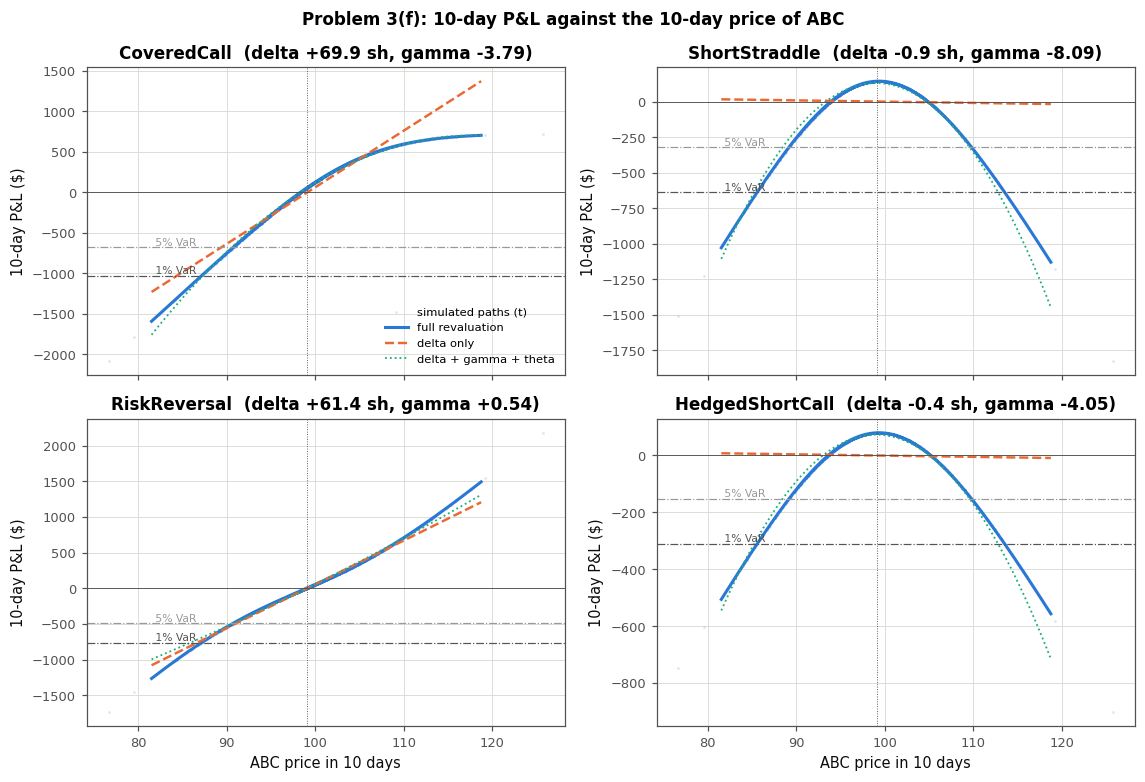

In [20]:
# Problem 3(f): full revaluation (line), simulated t paths (dots), delta-only and
#               delta+gamma+theta approximations, with the 5% and 1% VaR levels
problem3.figure_pnl(D3)

## Reconcile

### 3(g) What delta-normal cannot see; does adding gamma fix it?

> *Two books have a delta normal VaR close to zero. Explain what the delta normal method
> cannot see, using the second order expansion. Does adding the gamma term reproduce the
> full revaluation numbers?*

In [21]:
# Problem 3(g): VaR / ES of the delta, delta+gamma and delta+gamma+theta P&L on the SAME
#               simulated price paths, against full revaluation
TAY3 = problem3.part_g(D3)


Problem 3(g) - Taylor approximations vs full revaluation (same paths)

Normal paths
                                      mean    VaR5     ES5      VaR1       ES1
Portfolio       method                                                        
CoveredCall     delta                +0.10  586.83  724.86    812.38    917.67
                delta+gamma         -51.80  720.42  934.18  1,068.39  1,247.76
                delta+gamma+theta    +6.15  662.47  876.23  1,010.44  1,189.81
                full                 +6.22  680.51  874.05    996.89  1,146.55
ShortStraddle   delta                -0.00    7.85    9.93     11.25     12.93
                delta+gamma        -110.75  426.24  617.98    733.05    937.60
                delta+gamma+theta   +19.19  296.31  488.05    603.11    807.66
                full                +19.37  316.90  481.27    584.69    732.76
RiskReversal    delta                +0.09  515.26  636.46    713.30    805.75
                delta+gamma          +7.43  49

The ranking predicted in (a) held exactly. ShortStraddle and HedgedShortCall have
delta-normal 5% VaRs of **\$7.64 and \$3.82**. Full revaluation (Normal) gives
**\$316.90 and \$150.15**, about 40× larger. The covered call is understated (601 against
681) and the risk reversal slightly overstated (528 against 492), both as predicted.

The two delta-neutral books have $\delta \approx 0$, so delta-normal sees
$\Delta P \approx 0$. Their P&L is $\tfrac12\Gamma\Delta S^2 + \Theta\Delta t$, a parabola
opening downward (panel f). It has its maximum when the price does not move and loses
on a move in *either* direction. A linear method cannot represent a loss that depends on
$|\Delta S|$, and for a normal $\Delta S$ the parabola makes the P&L a shifted
chi-square, which no normal approximation of $\delta\Delta S$ can match.

**Adding gamma alone overshoots.** $\delta + \tfrac12\Gamma\Delta S^2$ gives \$426 for
the straddle, because it charges the convexity loss without the theta income that pays
for it: the mean of that P&L is −\$111 against the true +\$19. **Adding theta as well**
brings the 5% VaR to \$296 against the full \$317, and the mean to +\$19.19 against
+\$19.37. Further into the tail, the quadratic **overstates**: its 1% ES is \$808
against the full \$733 (Normal), and \$951 against \$836 under the $t$. A short option's
gamma is largest at the strike and decays as the price moves away, so a constant
$\Gamma$ extrapolates too much curvature into large moves (the dotted green curve in
panel f bends more than the blue one beyond ±\$10). The second-order expansion explains
*why* delta-normal fails and gets the body right. It does not reproduce the tail, and
only full revaluation does.

### 3(h) The mean P&L against the prediction in (b)

> *Compare the mean P&L from part (e) with your prediction in part (b). What is the short
> gamma books' positive mean paying for?*

In [22]:
# Problem 3(h): exact no-move P&L, and the mean P&L decomposed into an implied-minus-realised
#               variance spread plus a carry term
NM3 = problem3.no_move(D3)
MH3 = problem3.part_h(D3)


Problem 3(b)/(h) - P&L over 10 days if the price does not move
                P&L if S unchanged (exact) Theta x 10d (linear)
Portfolio                                                      
CoveredCall                         +60.55               +57.95
ShortStraddle                      +143.06              +129.94
RiskReversal                         +3.73                +0.73
HedgedShortCall                     +79.83               +73.26

Problem 3(h) - decomposing the mean 10-day P&L
realised vol = sd_daily x sqrt(255) = 0.2663; implied vols 0.27-0.32
variance spread = sum h x 0.5 G S^2 (RV^2 - IV^2) dt;  carry = sum h x r(V - delta S) dt

                theta 10d E[.5G dS^2] var spread   carry forecast sim mean N sim mean t    ES1 (t)
Portfolio                                                                                         
CoveredCall        +57.95      -51.80      +1.46   +4.69    +6.15      +6.22      +5.76  +1,225.30
ShortStraddle     +129.94     -110.52     +20.58

My prediction was correct in sign but too large in size. If the price does not move,
the books make +\$61, +\$143, +\$4 and +\$80. The *mean* P&L across the simulated paths is
only +\$6, +\$19, +\$9 and +\$18. The difference is the expected convexity loss
$E[\tfrac12\Gamma\Delta S^2] = \tfrac12\Gamma S^2\sigma_{RV}^2\Delta t$: −\$111 for the
straddle, which offsets most of its \$130 of theta. Paths where the price stays put are
not typical.

What is left is the price of the option. By the Black–Scholes PDE,
$\Theta = -\tfrac12\Gamma S^2\sigma_{IV}^2 + r(V - \delta S)$, so the expected P&L of
an option is $\tfrac12\Gamma S^2(\sigma_{RV}^2 - \sigma_{IV}^2)\Delta t$ plus a carry
term. The table decomposes it, and the forecast matches the simulated mean to within
50 cents for every book. For the straddle, **+\$20.58 is the variance spread** (sold at
29% implied against 26.6% realised) and −\$1.17 is carry. For the hedged short call,
\$10.29 is variance spread and \$7.71 is carry: the option price assumes the stock drifts
at $r$, while the scenario gives it zero drift.

So the short-gamma books' positive mean is a **volatility risk premium**: the market pays
the option seller for bearing a loss that is unbounded in $|\Delta S|$. The mean of
+\$19 pays for a 1% ES of \$733–836: one bad 1-in-100 outcome wipes out about 40 periods
of average profit. The trade is profitable on average, with a negatively skewed outcome.

### 3(i) Normal against $t$: which numbers move, and why the 5% VaR moves least

> *Switching from the normal to the $t$ moves some numbers far more than others. Which
> numbers, in which books, and why does the 5% VaR move least?*

In [23]:
# Problem 3(i): t / Normal ratios, the two fitted daily quantiles, where the CDFs cross,
#               and the quantiles of the compounded 10-day return
I3 = problem3.part_i(D3)


Problem 3(i) - ratio of t to Normal risk numbers
                VaR5 t/N ES5 t/N VaR1 t/N ES1 t/N mean t-N
Portfolio                                                 
CoveredCall        0.995   1.024    1.034   1.069    -0.46
ShortStraddle      1.018   1.081    1.093   1.141    +0.71
RiskReversal       0.995   1.028    1.038   1.081    -0.63
HedgedShortCall    1.019   1.084    1.095   1.144    +0.35

Daily return quantiles of the two fits (zero location):
         Normal         t t/Normal
alpha                             
0.050  -0.02740  -0.02642    0.964
0.010  -0.03875  -0.04297    1.109
0.001  -0.05148  -0.07190    1.397
The two daily CDFs cross at x = -0.03085, i.e. at the 3.20% quantile

10-day compounded return quantiles (simulated):
         Normal         t t/Normal
alpha                             
0.05   -0.08467  -0.08436    0.996
0.01   -0.11721  -0.12068    1.030


**What moves most:** the **1% ES of the two short-gamma books, up 14%** (straddle 733 →
836, hedged short call 358 → 410), followed by their 1% VaR (+9%) and 5% ES (+8%). The
two directional books move about half as much (1% ES +7–8%). **What moves least:** the
**5% VaR**, which changes by −0.5% to +2% in every book. The means barely change.

The reasons, in order:

1. **The two fits have the same variance**, and the $t$ redistributes mass from the
   shoulders to the centre and the far tails. The daily CDFs cross at the **3.2%
   quantile**. Above that point (including 5%) the $t$ quantile is *less* extreme
   than the Normal's (0.964×). Below it the $t$ is more extreme (1.11× at 1%, 1.40× at
   0.1%). A 5% statistic sits next to the crossing point, where the two distributions
   nearly agree.
2. **The 10-day horizon dilutes the tails.** A sum of 10 i.i.d. $t_{5.8}$ returns has
   one tenth of the daily excess kurtosis (CLT). At 10 days the $t$/Normal quantile
   ratios fall to 0.996 at 5% and 1.03 at 1%.
3. **ES averages the tail beyond the quantile**, so it picks up the far tail, which is
   where the $t$ differs. VaR is a single point near the crossing.
4. **Short gamma squares the difference.** The straddle's loss is $\propto\Delta S^2$,
   so a 3% wider tail in $\Delta S$ becomes about 6% in loss at the same quantile,
   and more in the ES average. The linear books (covered call, risk reversal) pass the
   tail through only once.

### 3(j) "Flat"

> *The hedged short call has no first order exposure. A risk manager says it is "flat."
> Write two sentences you would send in reply.*

> *It is flat only at today's price. With gamma of −4 it loses on a move in either
> direction (about \$200 of gamma loss on a \$10 move, against \$73 of theta over 10 days), its 10-day 1% ES is about \$360–410 against a
> delta-normal number of \$6, and it is short \$13.6 of vega per vol point. What it
> actually has is a short-volatility position that collects \$7 a day of theta for that
> risk, so it should be risk-limited on gamma and vega and re-hedged as the price
> moves, not reported as flat.*

---

# Problem 4 — A Sharpe Ratio That Sells Insurance

`problem4.csv`: 240 monthly total returns for EQ (an equity index), BOND, STK (a single
stock) and PUTW. PUTW sells a one-month put on EQ struck 5% out of the money each month
and holds the strike in cash. The risk-free rate is 3% a year, or
$r_{f,m} = 0.25\%$ a month. The annualised Sharpe ratio is
$\sqrt{12}\,(\bar r_m - r_{f,m})/s_m$.

## Predict

### 4(a) Moments and Sharpe ratios; the number that looks out of place

> *Compute the first four moments of each asset, and its annualized Sharpe ratio. If one
> number looks out of place, check how much of it comes from a single month.*


Problem 4(a) - monthly moments and annualised Sharpe ratios
rf_m = 0.00250 (3%/12); compounded alternative 0.00247

       mean/mo    sd/mo    skew  exkurt ann mean  ann sd Sharpe (ann)      min      max
asset                                                                                  
EQ     0.00790  0.04927  -0.387   3.519   0.0948  0.1707        0.380  -0.2351  +0.1999
BOND   0.00333  0.01346  +0.087   0.517   0.0399  0.0466        0.213  -0.0306  +0.0499
STK    0.01124  0.09327  -0.061   0.812   0.1349  0.3231        0.325  -0.3767  +0.3478
PUTW   0.00624  0.01655  -6.567  61.142   0.0749  0.0573        0.783  -0.1672  +0.0276

PUTW: 193 of 240 months return exactly 0.006385 (premium + interest, put expired worthless).
      20 months below that (the put paid off); 27 months above it.

Problem 4(a) - how much comes from a single month (leave the worst month out)
      worst month worst ret EQ that month skew all skew ex-worst exkurt all exkurt ex-worst SR all SR ex-worst
asse

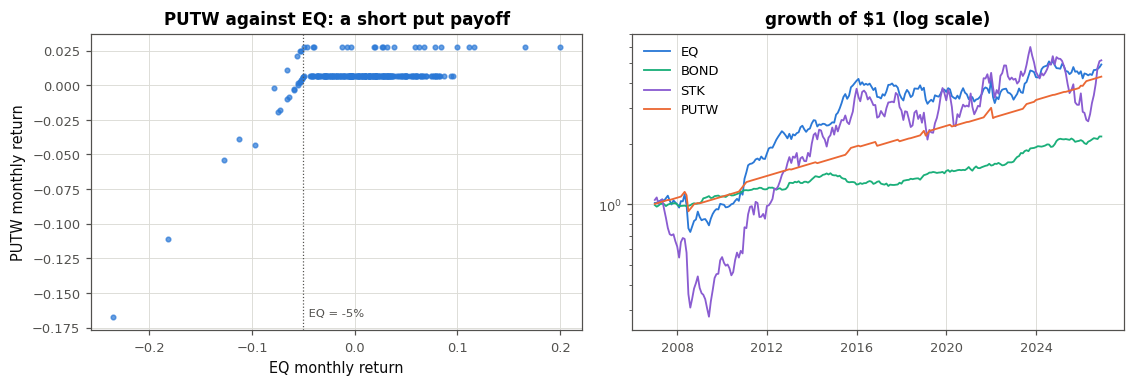

In [24]:
# Problem 4(a): moments, Sharpe ratios, PUTW's return distribution, and leave-the-worst-month-out
D4 = problem4.prepare()
M4 = problem4.part_a(D4)
problem4.figure_predict(D4)

**PUTW's Sharpe ratio of 0.78 is out of place.** It is twice EQ's (0.38) for a
strategy whose *risk is EQ's crash risk*, with less than EQ's return (7.5% against
9.5% a year). Its excess kurtosis of **61** and skew of **−6.6** are just as
extreme. The left panel shows why: PUTW is the payoff of a short put. In 193 of
240 months it earns exactly 0.6385% (premium plus interest, put expires worthless). In
27 high-volatility months it earns a larger premium of up to 2.76%. In 20 months
the put pays off and PUTW loses, up to −16.7% in 2008-06, when EQ fell 23.5%.

**A single month carries most of the shape.** Dropping 2008-06 alone raises PUTW's
Sharpe ratio from 0.78 to **1.27** and cuts its kurtosis from 61 to 41. The other
assets move much less (EQ 0.38 → 0.48). PUTW's sd is small because most months are
identical, not because the strategy is safe. Its risk shows up in a handful of
months, which is the situation the sample sd measures worst.

### 4(b) How much PUTW will the optimizer buy, and will its ES look Normal?

> *Before optimizing, predict how much weight a long only maximum Sharpe ratio portfolio
> will give PUTW. Then predict whether that portfolio's historical ES at 1% will be close to
> the ES of a normal with the same mean and standard deviation.*

The max-Sharpe optimizer sees only means and the covariance. PUTW has the highest
Sharpe ratio by a wide margin, the second-lowest sd, and a correlation with EQ well
below one (a linear fit cannot capture a short put's payoff). I predict the optimizer
will make PUTW the **core holding, around 60–80%**, with BOND as the diversifier
(the lowest-sd asset, roughly uncorrelated with PUTW in normal months), and with EQ and
STK near zero, since PUTW already delivers equity-like return at a fraction of EQ's
sd.

The historical 1% ES will be **far worse than the Normal ES**, perhaps 3× or more. A
Normal with PUTW-like sd (about 1.5% a month) has a 1% ES of only about 4%. The
historical 1% tail of 240 months is the two or three crash months, where PUTW lost
11–17%.

## Fit

### 4(c) Three maximum-Sharpe portfolios; frontier and CML

> *Find the maximum Sharpe ratio portfolio three ways: unconstrained, long only, and long
> only with PUTW capped at 20%. Plot the long only efficient frontier and the capital market
> line, with the four assets marked.*

The unconstrained tangency portfolio is the closed form
$w \propto \Sigma^{-1}(\mu - r_f)$, normalised so the weights sum to one. The constrained
versions are solved with SLSQP (multiple starts), as `optimizers.jl/maxSR` does with
Ipopt. The frontier solves the Week 07 minimum-variance problem for a grid of target
returns.


Problem 4(c) - maximum Sharpe ratio portfolios
                           EQ     BOND      STK     PUTW  mean/mo    sd/mo Sharpe (ann)
portfolio                                                                              
Unconstrained         -0.0439  +0.2465  +0.0227  +0.7747  0.00556  0.01295        0.820
Long only             +0.0000  +0.2607  +0.0092  +0.7301  0.00553  0.01287        0.815
Long only, PUTW<=20%  +0.1463  +0.6362  +0.0175  +0.2000  0.00472  0.01302        0.590


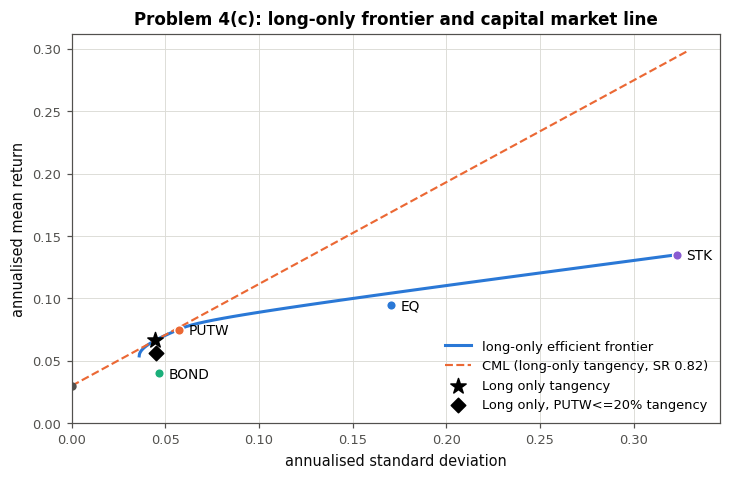

In [25]:
# Problem 4(c): tangency portfolios and the long-only frontier / CML
W4 = problem4.part_c(D4)
problem4.figure_frontier(D4)

The prediction was right. The long-only tangency portfolio is **73.0% PUTW, 26.1%
BOND, 0.9% STK and 0% EQ**, with an annualised Sharpe ratio of 0.815. Unconstrained, it
goes slightly short EQ (−4.4%), hedging part of PUTW's equity beta, and buys 77% PUTW
(SR 0.820): the long-only constraint barely binds. Capping PUTW at 20%
forces the optimizer into BOND (64%) and EQ (15%), and the Sharpe ratio drops to 0.59.
In the figure, PUTW sits almost on the CML. The tangency portfolio is essentially
PUTW, diversified with bonds.

### 4(d) Sharpe, historical and Normal VaR / ES for each portfolio

> *For each of the three portfolios, report the Sharpe ratio, and the historical and the
> normal VaR and ES at 5% and 1%.*

In [26]:
# Problem 4(d): monthly VaR / ES in % of value; historical (RiskStats.jl estimator) and Normal
RISK4 = problem4.part_d(D4)


Problem 4(d) - monthly VaR and ES (% of value, positive = loss)
                     Sharpe (ann) hist VaR5 norm VaR5 hist ES5 norm ES5
portfolio                                                              
Unconstrained               0.820     0.37%     1.57%    2.90%    2.11%
Long only                   0.815     0.29%     1.56%    2.93%    2.10%
Long only, PUTW<=20%        0.590     1.56%     1.67%    2.84%    2.21%
(asset) EQ                  0.380     5.95%     7.31%   10.30%    9.37%
(asset) BOND                0.213     2.12%     1.88%    2.49%    2.44%
(asset) STK                 0.325    13.50%    14.22%   17.55%   18.11%
(asset) PUTW                0.783     0.22%     2.10%    3.99%    2.79%

                     hist VaR1 norm VaR1 hist ES1 norm ES1 ES1 hist/norm
portfolio                                                               
Unconstrained            5.91%     2.46%   10.33%    2.90%         3.570
Long only                6.00%     2.44%   10.26%    2.88%         

For the long-only tangency portfolio:

| | 5% VaR | 5% ES | 1% VaR | 1% ES |
|---|---|---|---|---|
| historical | 0.29% | 2.93% | 6.00% | **10.26%** |
| Normal, same mean and sd | 1.56% | 2.10% | 2.44% | **2.88%** |

**The historical 1% ES is 3.6× the Normal's**, as predicted. The **5% historical VaR is
only 0.29%, below even the Normal's**: at the 5% quantile, PUTW's put has usually
just expired worthless, so VaR at 5% reports the strategy as nearly riskless. The whole
loss lies beyond the quantile. Capping PUTW at 20% halves the 1% ES (5.97%) and raises
the 5% VaR (1.56%) to about its Normal value. The tail ratio falls to 2.0×.

### 4(e) CAPM of PUTW on EQ, all months and the crash months

> *Run the CAPM regression of PUTW's excess return on EQ's excess return. Report $\alpha$,
> its $t$ statistic, $\beta$, and $R^2$. Then fit $\beta$ separately on the months when EQ's
> excess return was below −5%.*

In [27]:
# Problem 4(e): OLS of PUTW - rf on EQ - rf; then the 26 months with EQ - rf < -5%
CAPM4 = problem4.part_e(D4)


Problem 4(e) - CAPM of PUTW excess return on EQ excess return

all 240 months
  alpha = +0.00274/mo (+0.0329/yr)  se 0.00090  t = +3.05
  beta  = +0.1848  se 0.0182  t = +10.16  R^2 = 0.303

EQ excess < -5% (26 months)
  alpha = +0.05865/mo (+0.7038/yr)  se 0.00388  t = +15.13
  beta  = +0.9428  se 0.0432  t = +21.84  R^2 = 0.952

EQ excess >= -5% (214 months)
  alpha = +0.00540/mo (+0.0648/yr)  se 0.00046  t = +11.71
  beta  = +0.0430  se 0.0110  t = +3.92  R^2 = 0.067

mean EQ excess return +0.00540/mo; mean PUTW excess +0.00374/mo
alpha if PUTW were charged the downside beta on every month: -0.00135/mo


| sample | α (per month) | α t | β | R² |
|---|---|---|---|---|
| all 240 months | **+0.274%** (3.3%/yr) | **+3.05** | **0.185** | 0.30 |
| 26 months with EQ excess < −5% | | | **0.943** | 0.95 |
| 214 other months | | | 0.043 | 0.07 |

On the full sample, PUTW looks like a low-beta fund (0.18) with a significant 3.3% a year
alpha. In the 26 crash months its beta is **0.94**: it falls nearly one-for-one with the
market, exactly when the market is falling hard.

## Reconcile

### 4(f) What has the optimizer bought, and why can ES see it when Sharpe cannot?

> *What has the optimizer bought? Explain why the Sharpe ratio cannot see it, and use the
> coherence properties from Week 5 to say why ES can.*

**The optimizer has bought a short out-of-the-money put on the equity market**: about 73
cents per dollar of crash insurance written, with 26 cents of bonds. That is a steady
income in normal months and a large loss in a crash.

**The Sharpe ratio cannot see it** because it uses only the first two moments. Standard
deviation is symmetric, so it charges upside and downside dispersion equally. A short put
has no upside (its best month is the premium), so the sd is small even though the
downside is large. Most months are identical, which makes the sd smaller still. As Week
07 notes, standard deviation is a *deviation measure*: it is subadditive, positively
homogeneous and translation invariant, but **not monotone**. A strategy that loses more
than cash in every crash state can still have the lower sd, which is the case here.

**ES can see it**, because it is a coherent risk measure (Week 05):

* **Monotonicity.** If position A loses at least as much as B in every state, then
  ES(A) ≥ ES(B). The short put loses more than cash in every crash month, so ES must rank
  it as riskier. sd does not satisfy this.
* **It looks beyond the quantile.** ES is the average of the losses in the α tail, so the
  three crash months enter with their full size (10.3% at 1%). VaR is a single
  quantile, and here it is even gamed: the 5% VaR is 0.29% because the loss sits just
  beyond it. This is the standard way VaR fails coherence (non-subadditivity for
  short-option tails).
* **Subadditivity** means the strategy cannot be split into pieces that each look safe:
  ES of the combination never exceeds the sum. Positive homogeneity ensures scaling into
  PUTW scales the tail risk proportionally rather than hiding it.

An ES-based optimizer, such as `maxESR` in the class `optimizers.jl`, would cut the PUTW
weight sharply.

### 4(g) Is PUTW's alpha skill?

> *Is PUTW's CAPM alpha evidence of skill? Use the two betas from part (e) to explain what
> the single regression got wrong.*

**No.** The CAPM regression assumes PUTW's exposure is linear, one beta in all states.
A short put's exposure is close to zero when the market rises (β = 0.04, the put
expires worthless) and close to one when it falls far (β = 0.94, the put is deep in
the money). The single regression averages these into β = 0.18, which **under-charges
PUTW for its crash exposure**. The return that crash exposure earns, the put
premium, ends up in the intercept. If PUTW is charged its downside beta on every month,
its alpha becomes **−0.135% a month**.

The 3.3% a year "alpha" is the **insurance premium**: compensation for bearing equity
crash risk, plus the volatility risk premium that put writers earn (the same mechanism
as 3(h)). It requires no skill. Any mechanical put-writing rule earns it, and it is a
risk premium that a linear factor model cannot price. The right test would include a
downside-market or option-based factor, under which this alpha disappears.

### 4(h) How precisely do 240 months pin down the inputs?

> *Compute the standard error of each asset's mean monthly return. How precisely do 240
> months pin down the inputs to the optimizer? Use that to say which of the tangency weights
> you would trust. Resampling the months is one way to check.*


Problem 4(h) - standard error of each mean monthly return (sd/sqrt(240))
      mean/mo se(mean) t (mean>rf) ann mean ann 95% CI lo ann 95% CI hi
EQ    0.00790  0.00318       +1.70  +0.0948       +0.0200       +0.1696
BOND  0.00333  0.00087       +0.95  +0.0399       +0.0195       +0.0604
STK   0.01124  0.00602       +1.45  +0.1349       -0.0067       +0.2765
PUTW  0.00624  0.00107       +3.50  +0.0749       +0.0498       +0.1000

Problem 4(h) - long-only tangency weights when one mean moves by +/- 1 se


              EQ   BOND    STK   PUTW
shock                                
none       0.000  0.261  0.009  0.730
EQ -1se    0.000  0.261  0.009  0.730
EQ +1se    0.094  0.300  0.000  0.606
BOND -1se  0.000  0.000  0.010  0.990
BOND +1se  0.000  0.414  0.009  0.577
STK -1se   0.000  0.256  0.000  0.744
STK +1se   0.000  0.282  0.055  0.663
PUTW -1se  0.023  0.348  0.026  0.604
PUTW +1se  0.000  0.213  0.000  0.787



Problem 4(h) - bootstrap of the long-only tangency weights (2000 resamples)
      point boot mean boot sd     5%    50%    95% P(w > 1%)
EQ    0.000     0.021   0.062  0.000  0.000  0.120     0.218
BOND  0.261     0.256   0.216  0.000  0.221  0.659     0.827
STK   0.009     0.022   0.050  0.000  0.003  0.089     0.416
PUTW  0.730     0.701   0.237  0.240  0.742  1.000     0.986

Share of resamples that hold the weight PUTW > 50%: 80.8%


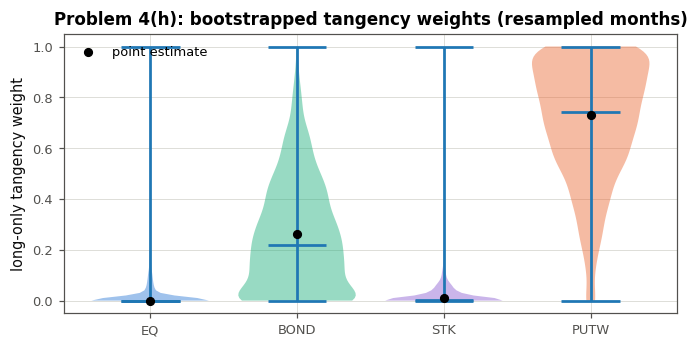

In [28]:
# Problem 4(h): se of each mean; tangency weights under +/- 1 se shocks; bootstrap of months
H4 = problem4.part_h(D4)
problem4.figure_boot(D4)

**The means are poorly determined.** With $se = s/\sqrt{240}$, EQ's mean is
0.79% ± 0.32% a month (an annual 95% CI of 2% to 17%). STK's is 1.12% ± 0.60% (−0.7% to
28%). BOND's is 0.33% ± 0.09%, which cannot be distinguished from the risk-free rate
($t = 0.95$). PUTW's appears the most precise (0.62% ± 0.11%, $t = 3.5$), but that
precision is an illusion. Its se is computed from an sd that the crash months make
unrepresentative, and whether the next 240 months contain two crashes or five changes
its mean far more than ±0.11%.

**Weights are unstable to input changes.** Moving a single mean by one standard error
moves the tangency weights by 10–40 points. BOND −1 se takes PUTW to 99%, and BOND +1 se
cuts it to 58%. The bootstrap (2,000 resamples of the 240 months) puts PUTW's weight
anywhere from **24% to 100%** (5th–95th percentile) and BOND's from **0 to 66%**.

**What I would trust:**

* **The zeros on EQ and STK**, mostly (median weight 0, under 12% at the 95th
  percentile). Given PUTW and BOND, the optimizer consistently finds no use for them.
* **The qualitative statement that PUTW dominates** (above 1% in 99% of resamples). But
  this is exactly the result 4(f) says not to trust, because it rests on the sd
  understating PUTW's risk.
* **Not the BOND/PUTW split** (73/26). It is determined by mean differences that are a
  fraction of a standard error, and the bootstrap spread of each weight is about ±20
  points.

Overall, 240 months fix the covariance reasonably well but the means hardly at all. An
optimizer fed sample means maximises estimation error (it overweights the assets whose
mean happened to come out high), so the weights should be treated as a point in a wide
cloud.

---

# Problem 5 — Alpha or Factor Exposure?

`problem5.csv`: 1,257 daily returns for FUND1 and FUND2, from 1996-10-01 to 2001-09-28.
The Fama–French factors and momentum are divided by 100, and excess return is fund
return minus that day's RF. Every fund date matches a factor date. Annualisation uses
255 trading days.

## Predict

### 5(a) Excess return, vol, Sharpe and CAPM

> *Compute each fund's mean excess return, volatility, and Sharpe ratio, and fit the CAPM.
> Which fund looks more skilled?*

In [29]:
# Problem 5(a): excess return, vol, Sharpe ratio and the CAPM regression for each fund
D5 = problem5.prepare()
A5 = problem5.part_a(D5)


Problem 5(a) - excess return, vol, Sharpe and CAPM
1257 matched days 1996-10-01 .. 2001-09-28 (fund file has 1257)

       mean ex/day ann mean ex   sd/day ann vol Sharpe (ann) CAPM alpha/day alpha ann alpha t   beta    R^2
fund                                                                                                       
FUND1     0.000624     +0.1590  0.01175  0.1876        0.848      +0.000441   +0.1124   +3.20  0.847  0.828
FUND2     0.000338     +0.0861  0.00719  0.1148        0.750      +0.000245   +0.0625   +1.83  0.429  0.567
Mkt-RF    0.000216     +0.0551  0.01262  0.2015        0.273                                               


| | excess return (ann) | vol (ann) | Sharpe | CAPM α (ann) | α t | β | R² |
|---|---|---|---|---|---|---|---|
| FUND1 | 15.9% | 18.8% | 0.85 | **11.2%** | **3.20** | 0.85 | 0.83 |
| FUND2 | 8.6% | 11.5% | 0.75 | 6.3% | 1.83 | 0.43 | 0.57 |

**On CAPM, FUND1 looks more skilled**: a higher Sharpe ratio and an 11.2% alpha with a
$t$ of 3.2, beside a market that earned 5.5% in excess over the same period. FUND2's alpha
is half as large and not significant at 5%.

### 5(b) Residual correlations, and what adding factors will do to alpha

> *Compute the correlation of each fund's CAPM residual with SMB, HML, and Mom. Predict what
> will happen to each fund's alpha when those factors are added to the regression.*

In [30]:
# Problem 5(b): corr(CAPM residual, factor) and the factor premia during the fund sample
B5 = problem5.part_b(D5)


Problem 5(b) - correlation of each fund's CAPM residual with the factors
          SMB     HML     Mom
fund                         
FUND1  -0.061  +0.205  +0.801
FUND2  +0.330  -0.121  +0.053

|rho| > 2/sqrt(n) = 0.056 is significant at ~5%.

Factor premia in the fund sample (1996-10 .. 2001-09):
              Mkt-RF       SMB       HML       Mom
mean/day    +0.00022  -0.00016  +0.00037  +0.00078
ann mean    +0.05510  -0.04151  +0.09478  +0.19937
t (mean=0)  +0.60704  -0.76796  +1.71237  +2.75130


The CAPM residual of **FUND1 has a 0.80 correlation with Mom** and 0.21 with HML.
Most of what CAPM calls idiosyncratic is momentum. FUND2's residual is correlated with
**SMB (+0.33)** and slightly negatively with HML.

An omitted factor's premium moves into alpha in proportion to the fund's loading:
$\alpha_{CAPM} \approx \alpha_{true} + \sum_k \beta_k\,\bar f_k$. In this sample
momentum earned **+19.9% a year** and HML +9.5%, while SMB **lost 4.2%**.

* **FUND1's alpha will collapse**, most of it into a momentum beta and some into HML.
  With 0.80 residual correlation and a 20% momentum premium, I expect little or no alpha
  to remain.
* **FUND2's alpha will rise slightly.** Its small-cap tilt *cost* it money in a sample
  where small caps lagged, so CAPM's alpha was *understated*. Adding SMB credits the
  fund for that headwind.

## Fit

### 5(c) CAPM, Fama–French 3 and Carhart 4

> *Fit the CAPM, the Fama French three factor model, and the Carhart four factor model to
> each fund. Report each coefficient with its standard error, the alpha's $t$ statistic,
> $R^2$, and AICc.*


Problem 5(c) - CAPM, FF3 and Carhart-4: coefficient (se)

FUND1   (alpha annualised: x 255)
                    alpha         Mkt-RF            SMB            HML            Mom alpha t     R^2      AICc
model                                                                                                          
CAPM      +0.1124(0.0351)  +0.847(0.011)                                                +3.20  0.8279   -9812.4
FF3       +0.0756(0.0334)  +1.002(0.017)  +0.083(0.020)  +0.335(0.029)                  +2.26  0.8452   -9941.7
Carhart4  +0.0007(0.0178)  +0.949(0.009)  +0.001(0.011)  +0.291(0.015)  +0.394(0.007)   +0.04  0.9563  -11530.4
  AICc differences vs best (Carhart4): CAPM +1718.0, FF3 +1588.7, Carhart4 +0.0

FUND2   (alpha annualised: x 255)
                    alpha         Mkt-RF            SMB            HML            Mom alpha t     R^2      AICc
model                                                                                                          
CAPM    

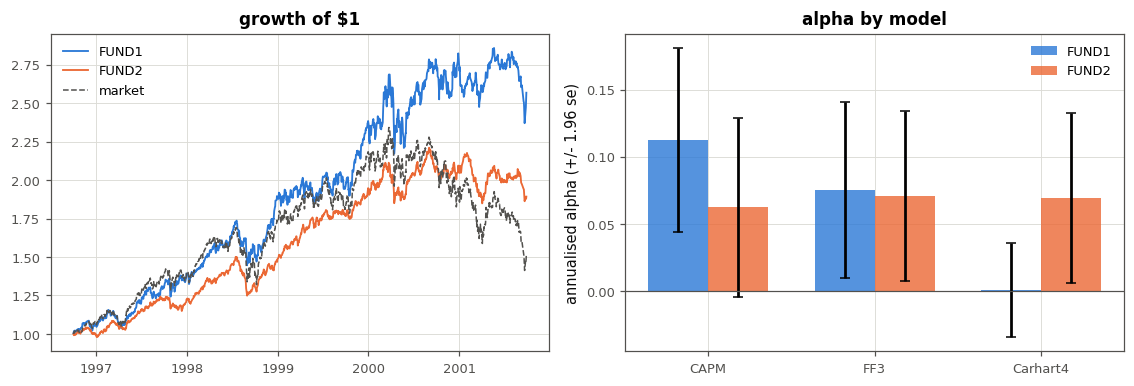

In [31]:
# Problem 5(c): OLS for all three models; alpha annualised x 255; AICc with k = p + 1
C5 = problem5.part_c(D5)
problem5.figure(D5)

**FUND1:** α falls from 11.2% (CAPM) to 7.6% (FF3, $t$ = 2.26) to **0.07% under Carhart
($t$ = 0.04)**. The fund loads **0.39 on momentum** ($t$ = 56) and 0.29 on HML, with a
market beta of 0.95. $R^2$ rises from 0.83 to 0.96, and AICc prefers the four-factor
model by about 1,600 units.

**FUND2:** α *rises* from 6.3% to **7.1% (FF3, $t$ = 2.26)** and stays at 7.0% under
Carhart ($t$ = 2.15). It loads 0.21 on SMB, nothing on HML and nothing on momentum
(0.006, se 0.013). AICc prefers FF3 by 1.8 units over Carhart: momentum adds a parameter
and no fit.

### 5(d) Expected annual return from the four-factor betas

> *Using the four factor betas, compute each fund's expected annual return under the average
> factor returns of the most recent 10 years in the factor files. Report it with and without
> the fitted alpha.*

In [32]:
# Problem 5(d): E[r] = 255 (alpha + beta' E[f]) + 255 E[RF], E[f] over 2014-10 .. 2024-09
E5 = problem5.part_d(D5)


Problem 5(d) - expected annual return from the 4-factor betas
Recent window: 2014-10-01 .. 2024-09-30 (2516 days)

       recent 10y mean/day recent 10y ann fund-sample ann
Mkt-RF           +0.000490        +0.1249         +0.0551
SMB              -0.000047        -0.0119         -0.0415
HML              -0.000094        -0.0239         +0.0948
Mom              +0.000097        +0.0246         +0.1994
RF               +0.000062        +0.0157         +0.0500

      E[excess] no a E[total] no a alpha (ann) E[total] with a realised total realised excess
fund                                                                                         
FUND1        +0.1213       +0.1371     +0.0007         +0.1378        +0.2090         +0.1590
FUND2        +0.0532       +0.0689     +0.0696         +0.1385        +0.1360         +0.0861

Contribution to the expected annual return (beta x 255 x recent mean):
          FUND1    FUND2
Mkt-RF  +0.1186  +0.0554
SMB     -0.0000  -0.0025
HML     -0.0

Over the most recent 10 years (2014-10 to 2024-09) the market earned 12.5% a year in
excess, while SMB (−1.2%) and HML (−2.4%) were negative and momentum (+2.5%) was small.
The risk-free rate averaged 1.6%.

| | expected, no α | expected, with α | realised in sample (total) |
|---|---|---|---|
| FUND1 | 13.7% | 13.8% | 20.9% |
| FUND2 | 6.9% | **13.9%** | 13.6% |

FUND1's expectation is almost all market beta (11.9 of 13.7 points). For FUND2, the
alpha decides the answer: it doubles the expected return.

### 5(e) A repeat of the worst momentum day

> *Find the worst daily momentum return in the factor file. Using the four factor betas,
> compute the one day loss on \$10,000,000 in each fund if it happened again with the other
> factors flat. Express each loss as a multiple of that fund's daily standard deviation in
> the sample.*

In [33]:
# Problem 5(e): worst Mom day in the full file through beta_Mom, on $10m
E5e = problem5.part_e(D5)


Problem 5(e) - the worst daily momentum return, through the 4-factor beta
Worst Mom day in the file: 1939-09-05  Mom = -0.1844 (-23.5 full-history sd)

      beta_Mom fund return P&L on $10m daily sd loss / daily sd worst day in sample worst / sd
fund                                                                                          
FUND1  +0.3936    -7.2571%    -725,709  0.01175            6.18            -6.8096%       5.80
FUND2  +0.0058    -0.1076%     -10,758  0.00719            0.15            -3.7715%       5.25


The worst momentum day in the file is **1939-09-05, −18.44%**, 23 full-history standard
deviations. Through its momentum beta of 0.394, **FUND1 would lose 7.26%, or \$725,709 on
\$10m: 6.2 of its daily standard deviations.** That is larger than its worst day in
the sample (−6.8%), and the loss is in a factor the fund's CAPM description never
mentions. FUND2 would lose \$10,758 (0.15 sd), because it has no momentum exposure.

## Reconcile

### 5(f) Did the alphas move as predicted?

> *Did the alphas move as you predicted? Use the factor premia during the sample to account
> for the change in FUND1's alpha.*

In [34]:
# Problem 5(f): exact decomposition, alpha_CAPM - alpha_4F = d(beta_mkt) mkt_bar + sum beta_k f_k_bar
F5 = problem5.part_f(D5)


Problem 5(f) - CAPM alpha minus 4-factor alpha, by factor (annualised)
fund                FUND1    FUND2
alpha CAPM        +0.1124  +0.0625
alpha 4F          +0.0007  +0.0696
drop              +0.1116  -0.0071
d beta_mkt x mkt  +0.0056  +0.0008
beta_SMB x SMB    -0.0000  -0.0087
beta_HML x HML    +0.0276  -0.0004
beta_Mom x Mom    +0.0785  +0.0012
sum of parts      +0.1116  -0.0071


**Yes, in direction and in size.** OLS passes through the means
($\alpha = \bar y - \sum_k \beta_k \bar f_k$ in every model), so the change in alpha
decomposes *exactly* into loadings × in-sample premia. For FUND1 the 11.16-point drop
(annualised) is:

| source | contribution |
|---|---|
| momentum: 0.394 × 19.9% | **7.85** |
| value: 0.291 × 9.5% | 2.76 |
| market beta rising from 0.847 to 0.949, × 5.5% | 0.56 |
| size: 0.001 × (−4.2%) | 0.00 |
| **total** | **11.16** |

FUND1's alpha was **momentum and value exposure** earned in a period when momentum
paid 20% a year. FUND2's alpha went the predicted way and rose by 0.71 points: SMB's −4.2% premium
times its 0.21 loading contributes +0.87, partly offset by small market and momentum
terms.

### 5(g) APT, alpha, and which fee to pay

> *Use Arbitrage Pricing Theory to explain what an alpha is relative to a factor model. Which
> fund would you pay a fee for alpha, and which model would you use to decide? Label your
> answer as an opinion where it is one.*

APT (Week 07) says that if returns follow a linear factor structure, the absence of
arbitrage forces $E[r_s - r_f] = \sum_k \beta_k RP_k$. Expected return is compensation for
exposure to priced factors and nothing else. **Alpha is defined relative to a chosen
factor model**: it is the part of the mean return that the model's factors do not explain.
An "alpha" under CAPM can be a beta under Carhart, as FUND1 shows. Whether alpha exists
is therefore not a property of the fund alone. It depends on which factors the investor
can already buy cheaply. Factor exposure can be bought with index or factor funds for a
few basis points, so it is not worth an alpha fee.

**Fact:** FUND1 has no alpha under the four-factor model (0.07% a year, $t$ = 0.04), so
its excess return is replicable with market, value and momentum exposures. FUND2 keeps a
7% a year alpha with $t \approx 2.2$ under both FF3 and Carhart.

**Opinion:** I would **not pay FUND1 an alpha fee**. It is a momentum-and-value fund,
with a large unhedged momentum crash risk (part (e)). **FUND2 is the only candidate.** I
would decide with the **richest model the evidence supports, Carhart four-factor**, because
the fee question is "what can I not replicate cheaply?" and every factor that can be
replicated should be in the benchmark. AICc picks FF3 for FUND2, but the two give the same
alpha, so the choice does not change the answer. Even so, a $t$ of 2.2 on five years is
only moderate evidence. It would fall below 2 if this were one of several funds screened,
and FUND2's alpha might load on factors not tested here (profitability, low volatility).
I would pay a fee well below the 7%, and keep reviewing it.

### 5(h) Expected returns from a factor model, against realised

> *Compare part (d) with each fund's realized return in the sample. What does that say about
> building expected returns for an optimizer, like the one in Problem 4, from a factor
> model?*

FUND1 realised **20.9%** a year in the sample, but the four-factor model with recent
premia expects **13.7%**. The 7-point gap is almost entirely the factor premia changing
between the two windows. Momentum fell from 19.9% to 2.5% a year and HML from +9.5% to
−2.4%, while the market's rose from 5.5% to 12.5%. FUND2's realised 13.6% happens to
match its with-alpha forecast (13.9%), but without alpha the model says 6.9%. Its
answer depends entirely on whether the alpha is real.

The lessons for an optimizer like Problem 4's:

1. **A factor model moves the estimation problem, it does not remove it.** Betas are
   estimated precisely (FUND1's momentum beta has $t$ = 56), but expected return is
   beta × *premium*, and premia measured over 5 or 10 years are as noisy as the asset
   means in 4(h). The same betas give very different expected returns depending on the
   premium window.
2. **The fitted alpha is the most dangerous input.** It is the least precisely estimated
   number (FUND2: 7% ± 3.2%), and an optimizer will load on it heavily. Standard practice
   is to shrink alpha toward zero unless there is strong out-of-sample evidence.
3. **The approach is still better than raw sample means**, because it estimates a few
   factor premia instead of N asset means and imposes a structure in which similar assets
   get similar expected returns. But the premia should come from long histories or
   economic priors, and the optimizer should be constrained, or resampled as in 4(h),
   so that small changes in the premia do not produce large changes in weights.